# PokerAI: Statistical Analysis

In this notebook, we look at how CFR, CFR+, Q-learning and Deep Q-Networks perform in Kuhn and Leduc Poker. We focus on three questions:

1. Which approaches produce strategies that are difficult to exploit?
2. How does profitability against weaker opponents compare with robustness against stronger ones?
3. How closely do finite Monte Carlo simulations agree with exact expected values?

This analysis uses the saved experiment results rather than retraining the agents.

## 1. Load the experimental results

The results are stored in `results/kuhn/` and `results/leduc/`.

For Kuhn, We use a known Nash equilibrium as a useful reference. For Leduc, we use the saved CFR+ strategy as a strong reference opponent, although it is not an exact Nash equilibrium.

All expected values represent net chips won per hand. Positive values favour the named agent. The evaluation balances player positions.

CFR training budgets are measured in full game tree iterations, while Q-learning and DQN budgets are measured in sampled hands. They cannot be compared as equivalent units of computation.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

root = Path.cwd()
if not (root / "results").exists():
    root = root.parent

results = root / "results"

kuhn = pd.read_csv(results / "kuhn/kuhn_final_benchmark.csv")
kuhn_cfr = pd.read_csv(results / "kuhn/cfr_comparison.csv")

leduc = pd.read_csv(results / "leduc/agent_summary.csv")
leduc_cfr = pd.read_csv(results / "leduc/cfr_comparison.csv")
head_to_head = pd.read_csv(
    results / "leduc/head_to_head_matrix.csv", index_col="agent"
)
monte_carlo = pd.read_csv(results / "leduc/monte_carlo_summary.csv")
sessions = pd.read_csv(results / "leduc/monte_carlo_sessions.csv")

plt.rcParams.update({
    "figure.facecolor": "lightsteelblue",
    "axes.facecolor": "lemonchiffon",
    "savefig.facecolor": "auto",
    "axes.titleweight": "bold",
})

pd.set_option("display.precision", 4)

print(f"Kuhn agents: {len(kuhn)}")
print(f"Leduc agents: {len(leduc)}")
print(f"Monte Carlo sessions: {len(sessions)}")


Kuhn agents: 8
Leduc agents: 6
Monte Carlo sessions: 300


## 2. Which strategies are hardest to exploit?

**Exploitability** measures how much an optimal opponent can gain by responding to a fixed strategy. Lower exploitability indicates greater robustness.

In a two player zero sum game, an exact Nash equilibrium has zero exploitability. This provides a useful measure of whether an agent is learning generally strong poker strategies rather than simply exploiting the opponents it encountered during training.


In [2]:
columns = ["agent", "exploitability", "ev_vs_random"]

print("Kuhn Poker")
display(kuhn[columns].sort_values("exploitability").reset_index(drop=True))

print("Leduc Poker")
display(leduc[columns].sort_values("exploitability").reset_index(drop=True))


Kuhn Poker


,agent,exploitability,ev_vs_random
0,Nash,4.1633e-17,0.1667
1,CFR+,9.6328e-06,0.1482
2,CFR,2.3178e-03,0.1471
3,Q-learning Random,3.3333e-01,0.4583
4,Q-learning Mixed,3.3333e-01,0.4583
5,DQN Random Huber,3.3333e-01,0.4583
6,DQN Mixed MSE,3.3333e-01,0.4583
7,DQN Mixed Huber,5.0000e-01,0.3750


Leduc Poker


,agent,exploitability,ev_vs_random
0,CFR+,0.0050,0.7180
1,CFR,0.0980,0.8214
2,Q-learning Mixed,2.3333,1.5309
3,DQN Mixed,2.7667,2.0185
4,DQN Random,3.2833,2.2238
5,Q-learning Random,3.3833,2.1122


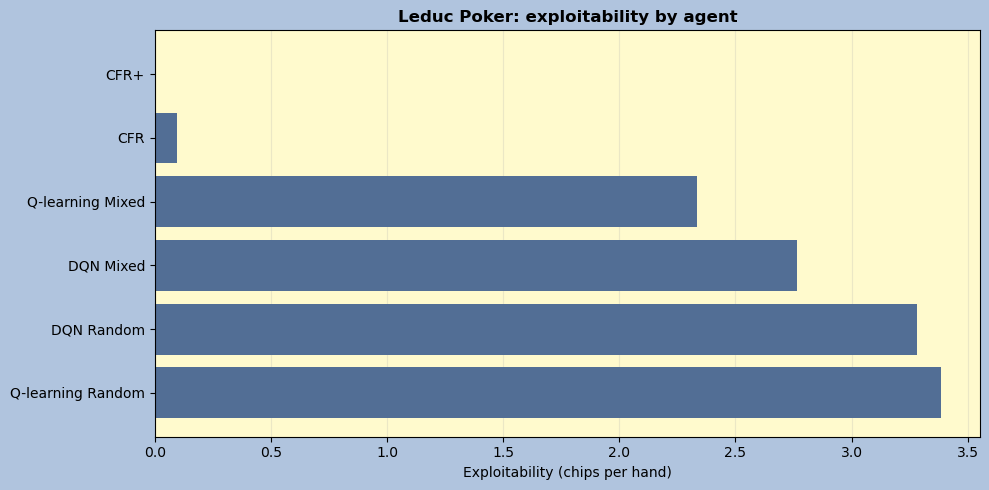

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
data = leduc.sort_values("exploitability")

ax.barh(data["agent"], data["exploitability"], color="#526e95")
ax.invert_yaxis()
ax.set_xlabel("Exploitability (chips per hand)")
ax.set_title("Leduc Poker: exploitability by agent")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Interpretation**

CFR+ achieves an exploitability of approximately **0.0050**, compared with **0.0980** for ordinary CFR.

The most robust reinforcement learning policy is Q-learning Mixed, with exploitability of **2.3333**. Even this is substantially more exploitable than the CFR approaches.

This suggests that the reinforcement learning agents have learned useful opponent specific behaviour, but have not approached an equilibrium strategy in Leduc.


## 3. CFR versus CFR+: Convergence

We next compare how quickly the equilibrium based algorithms reduce exploitability.

Each CFR iteration explores the full game tree. This makes iteration count meaningful when comparing CFR and CFR+, although the computational cost per iteration is not identical.


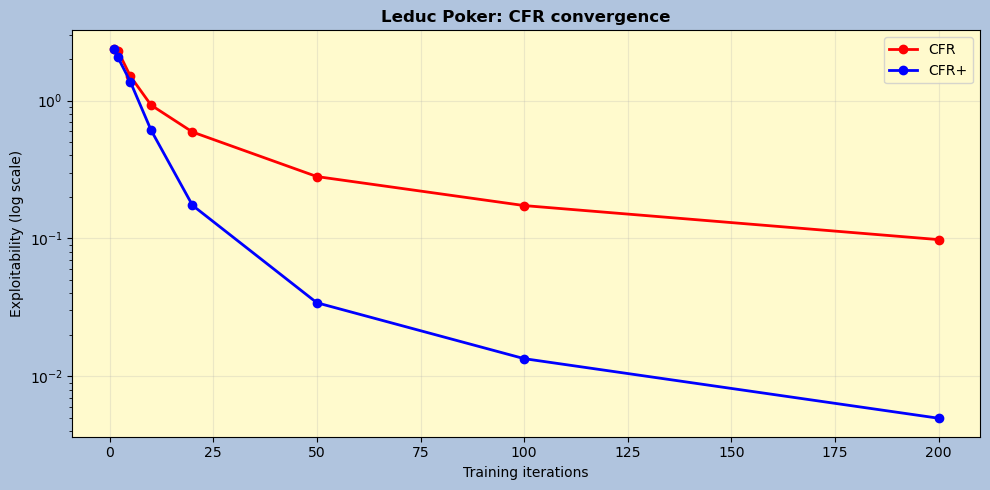

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

for name, color in [("CFR", "red"), ("CFR+", "blue")]:
    data = leduc_cfr[leduc_cfr["algorithm"] == name]
    ax.plot(
        data["iterations"],
        data["exploitability"],
        marker="o",
        color=color,
        label=name,
        linewidth=2
    )

ax.set_yscale("log")
ax.set_xlabel("Training iterations")
ax.set_ylabel("Exploitability (log scale)")
ax.set_title("Leduc Poker: CFR convergence")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [5]:
final_convergence = (
    leduc_cfr.sort_values("iterations")
    .groupby("algorithm")
    .tail(1)
    [["algorithm", "iterations", "exploitability", "training_seconds"]]
)

display(final_convergence.reset_index(drop=True))


,algorithm,iterations,exploitability,training_seconds
0,CFR,200,0.098,32.6936
1,CFR+,200,0.005,62.7340


**Interpretation**

At 200 iterations, CFR+ achieves approximately **0.00496** exploitability while CFR reaches **0.09797**.

CFR+ is considerably closer to equilibrium at the same iteration count, but takes approximately **62.7 seconds** compared with **32.7 seconds** for CFR. A lower exploitability per iteration does not automatically imply a lower computational cost.


## 4. Profitability versus robustness

A profitable strategy is not necessarily a robust strategy.

An agent may perform extremely well against Random by exploiting predictable behaviour, while losing money against a stronger opponent. To investigate this, we compare expected profit against Random with exploitability and performance against CFR+.


In [6]:
display(
    leduc[
        ["agent", "ev_vs_random", "ev_vs_cfr_plus",
         "mean_ev_vs_other_agents", "exploitability"]
    ]
    .sort_values("ev_vs_random", ascending=False)
    .reset_index(drop=True)
)


,agent,ev_vs_random,ev_vs_cfr_plus,mean_ev_vs_other_agents,exploitability
0,DQN Random,2.2238,-0.5135,-0.2080,3.2833
1,Q-learning Random,2.1122,-0.6016,-0.5179,3.3833
2,DQN Mixed,2.0185,-0.4379,-0.2919,2.7667
3,Q-learning Mixed,1.5309,-0.1803,0.2614,2.3333
4,CFR,0.8214,-0.0226,0.4052,0.0980
5,CFR+,0.7180,0.0000,0.3512,0.0050


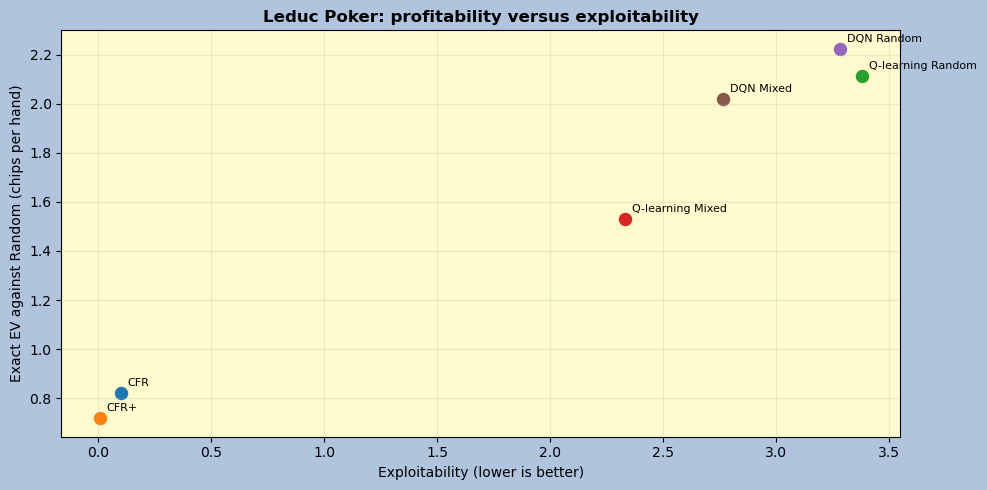

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

for _, row in leduc.iterrows():
    ax.scatter(row["exploitability"], row["ev_vs_random"], s=75)
    ax.annotate(
        row["agent"],
        (row["exploitability"], row["ev_vs_random"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Exploitability (lower is better)")
ax.set_ylabel("Exact EV against Random (chips per hand)")
ax.set_title("Leduc Poker: profitability versus exploitability")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


**Interpretation**

DQN Random achieves the largest expected profit against Random at **+2.2238 chips per hand**. However, it loses approximately **0.5135 chips per hand** against CFR+.

Q-learning Mixed earns less against Random at **+1.5309**, but loses only **0.1803** against CFR+ and is the least exploitable reinforcement learning agent.

These results highlight the distinction between exploiting a particular opponent and maintaining a strategy that is difficult to exploit. The results do not establish that one algorithm is universally superior. The final models come from specific training settings and limited training runs.


## 5. Head to head performance

The head to head matrix evaluates each saved Leduc policy against the others using exact expected value.

The first agent is represented by the row and the opponent by the column. Positive values mean the row agent is expected to profit. Both seat positions receive equal weight.


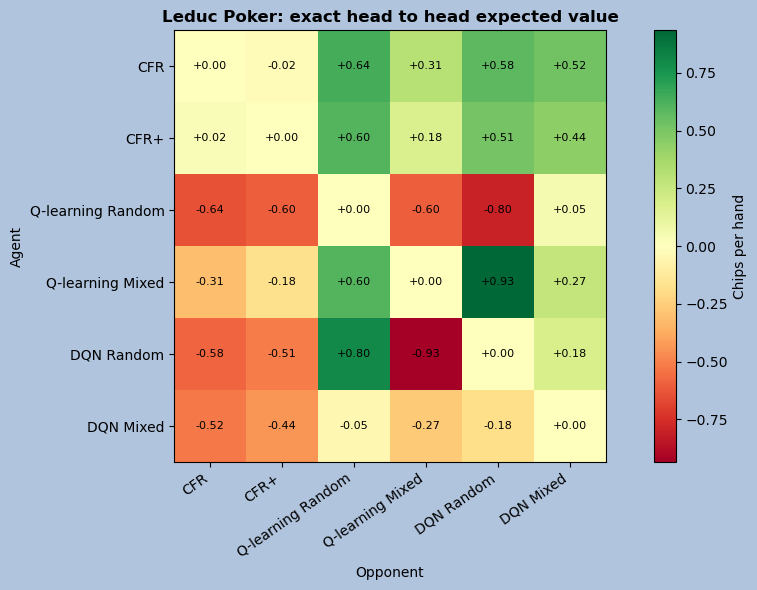

In [16]:
values = head_to_head.to_numpy()

assert np.allclose(values, -values.T, atol=1e-10)
assert np.allclose(np.diag(values), 0, atol=1e-10)

fig, ax = plt.subplots(figsize=(10, 6))
limit = np.max(np.abs(values))

heatmap = ax.imshow(values, cmap="RdYlGn", vmin=-limit, vmax=limit)

ax.set_xticks(
    range(len(head_to_head.columns)),
    head_to_head.columns,
    rotation=35,
    ha="right"
)
ax.set_yticks(range(len(head_to_head.index)), head_to_head.index)

for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        ax.text(
            j, i, f"{values[i, j]:+.2f}",
            ha="center", va="center", fontsize=8
        )

ax.set_xlabel("Opponent")
ax.set_ylabel("Agent")
ax.set_title("Leduc Poker: exact head to head expected value")
fig.colorbar(heatmap, ax=ax, label="Chips per hand")

plt.tight_layout()
plt.show()


**Interpretation**

CFR+ performs positively against all five other trained agents. Ordinary CFR has the highest average EV against the selected opponent pool at approx **+0.4052**, compared with **+0.3512** for CFR+.

This is not a contradiction. CFR+ is less exploitable and wins the direct comparison against CFR, while ordinary CFR happens to earn more against this particular mix of other agents in this tournament.

Among the reinforcement learning policies, Q-learning Mixed performs particularly well in direct matchups, earning approx **+0.9333** against DQN Random.

The average tournament payoff depends on which opponents are included, so this is not an absolute ranking of poker skill.


## 6. Monte Carlo validation

The exact expected values are calculated by considering all possible deals and action branches. Monte Carlo simulation instead estimates these values from played hands.

The final experiment contains:

- 15 unique agent matchups
- 20 independent sessions per matchup
- 1,000 simulated hands per session
- 300,000 simulated hands in total

Each session balances the two player positions.

We treat the **session average** as the independent observation when estimating uncertainty, rather than treating individual actions or cards as independent data points.

For each matchup, the estimated mean and standard error are:

$$ \widehat{\\mu}=\frac{1}{n}\sum_{i=1}^{n}\overline X_i $$

$$ SE(\widehat{\\mu})= \frac{s}{\sqrt n} $$

Here $n=20$, $\overline X_i$ is the average profit in session $i$, and $s$ is the sample standard deviation of the session averages.

I use a **95%** Student $t$ interval with 19 degrees of freedom. It measures uncertainty in the simulated mean EV, not the outcome of any individual session.


In [ ]:
monte_carlo["error"] = (monte_carlo["simulated_ev"] - monte_carlo["exact_ev"])

display(
    monte_carlo[
        ["agent_a", "agent_b", "exact_ev", "simulated_ev",
         "ci_lower_95", "ci_upper_95", "exact_ev_inside_ci"]
    ].round(4)
)

covered = int(monte_carlo["exact_ev_inside_ci"].sum())
total = len(monte_carlo)

print(f"Exact EV inside 95% CI: {covered}/{total}")
print(
    "Mean absolute simulation error:",
    round(monte_carlo["absolute_error"].mean(), 4),
    "chips per hand"
) 


,agent_a,agent_b,exact_ev,simulated_ev,ci_lower_95,ci_upper_95,exact_ev_inside_ci
0,CFR,CFR+,-0.0226,-0.0168,-0.0428,0.0092,True
1,CFR,Q-learning Random,0.6379,0.6085,0.5597,0.6572,True
2,CFR,Q-learning Mixed,0.3127,0.3050,0.2516,0.3584,True
3,CFR,DQN Random,0.5764,0.6215,0.5423,0.7006,True
4,CFR,DQN Mixed,0.5215,0.5242,0.4278,0.6207,True
5,CFR+,Q-learning Random,0.6016,0.5611,0.4928,0.6293,True
6,CFR+,Q-learning Mixed,0.1803,0.1683,0.1165,0.2201,True
7,CFR+,DQN Random,0.5135,0.4747,0.4025,0.5469,True
8,CFR+,DQN Mixed,0.4379,0.4270,0.3758,0.4783,True
9,Q-learning Random,Q-learning Mixed,-0.6000,-0.5655,-0.6397,-0.4913,True


Exact EV inside 95% CI: 14/15
Mean absolute simulation error: 0.0195 chips per hand


### Exact EV versus simulated EV

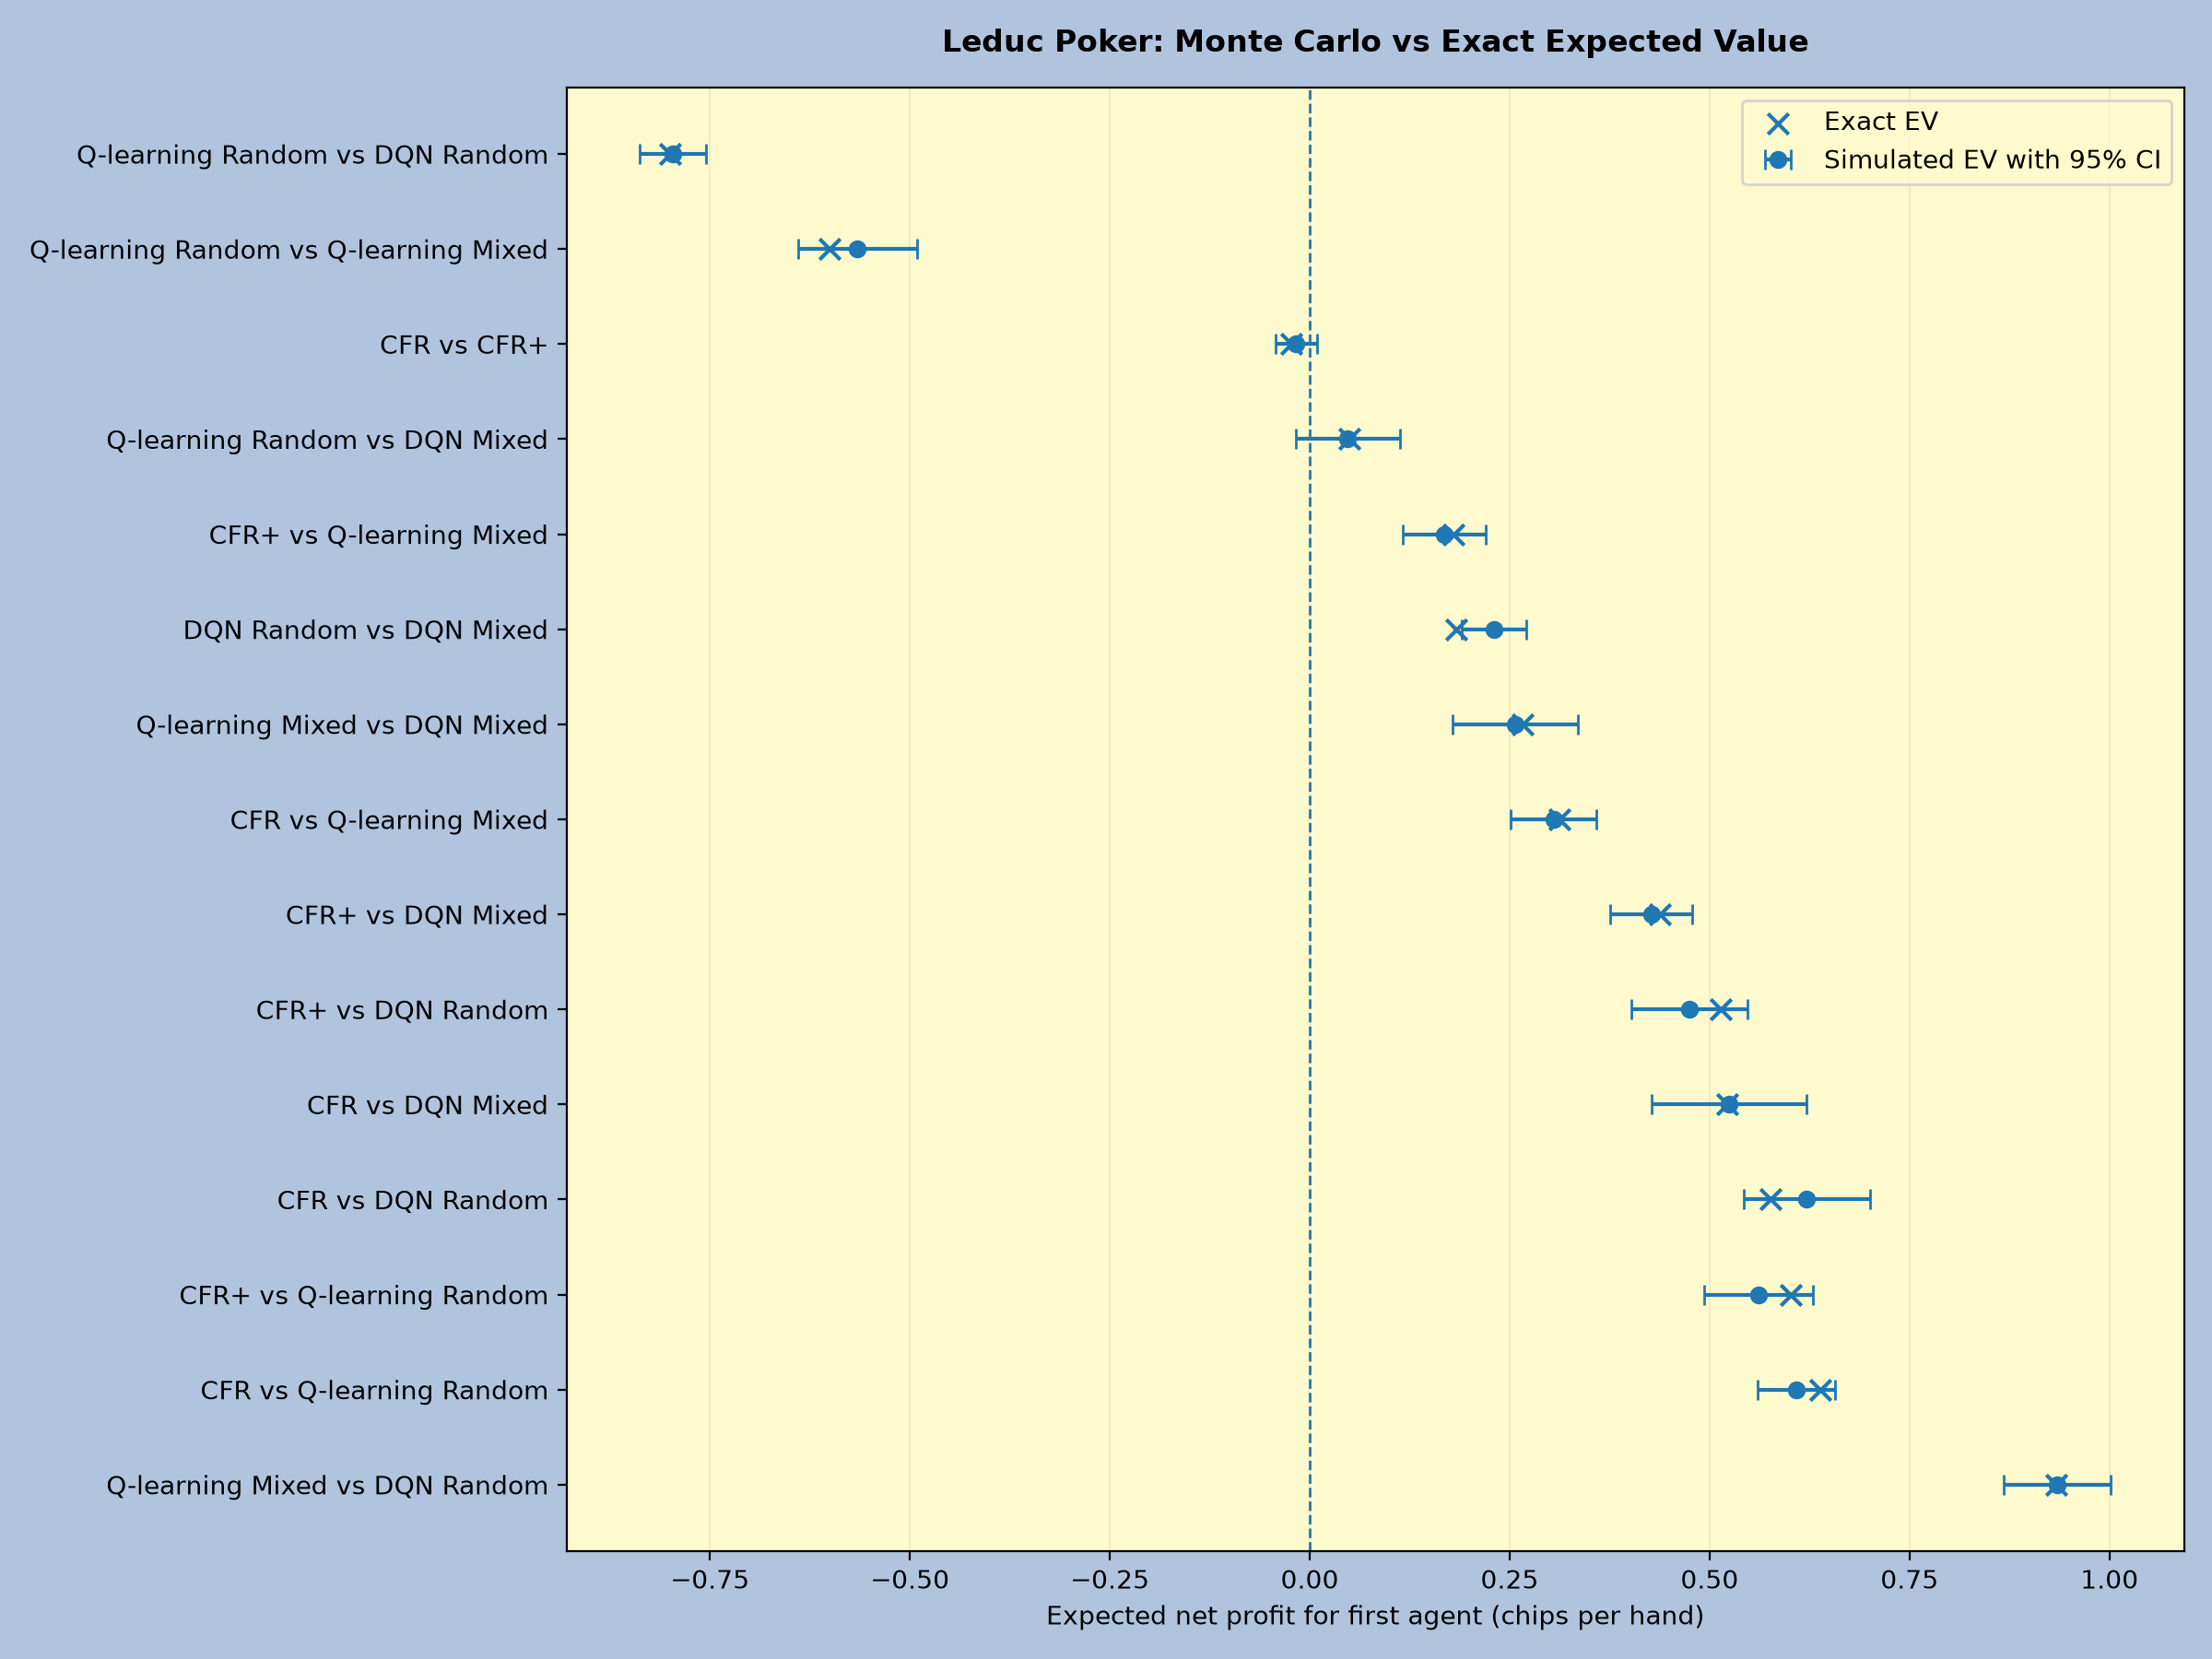

In [18]:
display(Image(
    filename=str(results / "leduc/monte_carlo_comparison.png"),
    width=950
))


**Interpretation**

The confidence intervals contain the exact EV for **14 of the 15 matchups**. The exception is DQN Random versus DQN Mixed, where the simulated estimate is **+0.2309**, compared with an exact EV of **+0.1833**. Its 95% confidence interval is approximately **[+0.1905, +0.2713]**.

A 95% confidence interval is not guaranteed to contain the true value in every experiment. This single exclusion does not by itself indicate a simulation error. The general agreement provides a useful cross check, although the exact evaluator and simulator still share the same underlying game rules.


### How variable are individual simulation sessions?

The CFR versus CFR+ matchup is particularly useful because the true difference is small.

The following saved graph shows the realised EV in each independent session. The shaded band represents uncertainty in the overall mean, not the range in which individual sessions should fall.


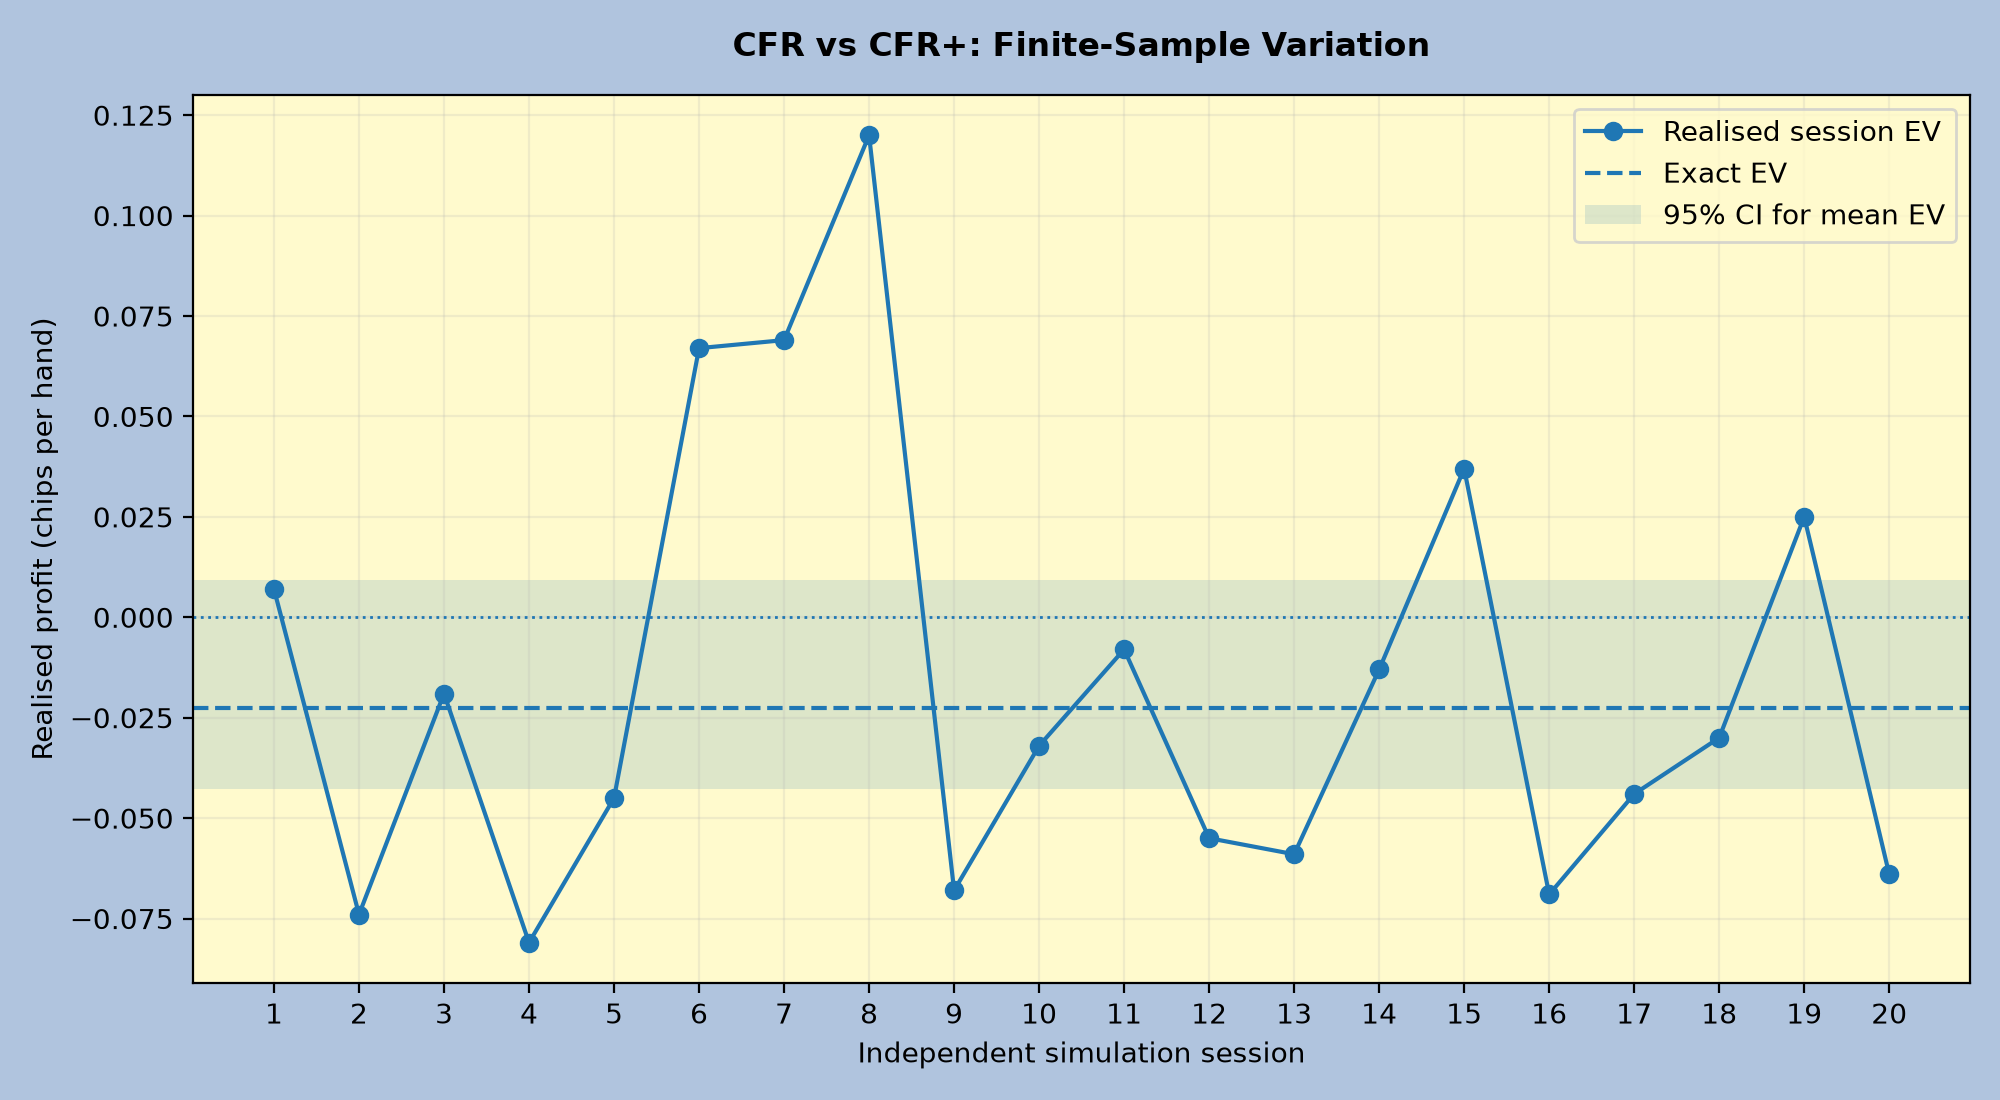

In [19]:
display(Image(
    filename=str(results / "leduc/monte_carlo_cfr_variance.png"),
    width=850
))


**Interpretation**

CFR has an exact EV of approximately **−0.02264** against CFR+. The mean simulated EV is **−0.0168**. Its 95% confidence interval is approximately **[−0.0428, +0.0092]**, which crosses zero. This shows why short simulations can be inconclusive even when the exact evaluation identifies which strategy has the advantage.


## 7. Kuhn versus Leduc

Kuhn contains 12 information sets, while this implementation of Leduc contains 288.

We use Kuhn as a smaller benchmark where an exact Nash policy is available. Leduc offers a more demanding setting with two betting rounds and a public card.


In [12]:
print("Selected Kuhn strategies")
display(
    kuhn[
        kuhn["agent"].isin(
            ["Nash", "CFR", "CFR+", "Q-learning Mixed", "DQN Mixed MSE"]
        )
    ][["agent", "exploitability", "ev_vs_random"]]
    .sort_values("exploitability")
    .reset_index(drop=True)
)

print("Leduc strategies")
display(
    leduc[["agent", "exploitability", "ev_vs_random"]]
    .sort_values("exploitability")
    .reset_index(drop=True)
)


Selected Kuhn strategies


,agent,exploitability,ev_vs_random
0,Nash,4.1633e-17,0.1667
1,CFR+,9.6328e-06,0.1482
2,CFR,2.3178e-03,0.1471
3,Q-learning Mixed,3.3333e-01,0.4583
4,DQN Mixed MSE,3.3333e-01,0.4583


Leduc strategies


,agent,exploitability,ev_vs_random
0,CFR+,0.0050,0.7180
1,CFR,0.0980,0.8214
2,Q-learning Mixed,2.3333,1.5309
3,DQN Mixed,2.7667,2.0185
4,DQN Random,3.2833,2.2238
5,Q-learning Random,3.3833,2.1122


**Interpretation**

The exact Nash policy in Kuhn has effectively zero exploitability, providing a useful theoretical reference. The trained CFR+ policy also comes very close to equilibrium. In Leduc, CFR+ remains substantially more robust than the reinforcement learning policies. We should not compare raw profitability directly between Kuhn and Leduc because their stakes, betting rules and possible payoffs differ.

## Conclusion

The results suggest three main findings.

**First**, CFR+ produces the strongest equilibrium oriented strategy in Leduc, with much lower exploitability than the other trained agents.

**Second**, reinforcement learning can produce profitable strategies against weak opponents without achieving strong robustness. The largest EV against Random does not correspond to the least exploitable agent.

**Third**, repeated Monte Carlo simulations broadly agree with exact expected values, but the variation between sessions can obscure small advantages.

### Limitations

The main limitation is that the final reinforcement learning comparisons use specific saved policies rather than distributions over many independent training seeds. Results could vary with different seeds, hyperparameters and training budgets.

The methods also have different computational costs and training units. The chosen opponent pool influences tournament rankings.

A future extension could be to repeat each training configuration across several independent seeds and compare the distribution of final performance rather than relying on individual runs.

Overall, the project demonstrates that evaluating an imperfect information agent requires looking at **profitability, exploitability and statistical uncertainty together**.
